# 04 – Baseline và mô hình tuyến tính

1. Baseline: dự đoán trung bình; trung bình theo giờ.
2. Mô hình tuyến tính: Linear Regression, Ridge, Lasso (cross-validation theo thời gian).
3. Phân tích hệ số.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data_loader import load_raw_data
from src.evaluate import HourMeanBaseline, MeanBaseline, metrics_table, regression_metrics
from src.features import make_xy
from src.split import time_split
from src.visualization import save_fig, set_style

warnings.filterwarnings("ignore", category=UserWarning)
set_style()
train, val, test = time_split(load_raw_data())
X_tr, y_tr = make_xy(train)
X_va, y_va = make_xy(val)
cols = list(X_tr.columns)
print("Train:", X_tr.shape, "| Validation:", X_va.shape)

Train: (13814, 31) | Validation: (2960, 31)


## 1. Baseline
- **MeanBaseline:** luôn dự đoán trung bình train (98,8 Wh) – mốc "không học gì".
- **HourMeanBaseline:** dự đoán trung bình theo giờ trong ngày học từ train – tận dụng chu kỳ ngày thấy trong EDA.

In [2]:
results = {}
for name, model in [("Baseline – trung bình", MeanBaseline()),
                    ("Baseline – trung bình theo giờ", HourMeanBaseline())]:
    model.fit(X_tr, y_tr)
    results[name] = regression_metrics(y_va, model.predict(X_va))
metrics_table(results)

,MAE,RMSE,R2,MAPE_%
Baseline – trung bình theo giờ,48.546,87.230,0.106,54.420
Baseline – trung bình,53.968,92.394,-0.003,67.726


Đã lưu hình: reports/figures/04_baseline_hour.png


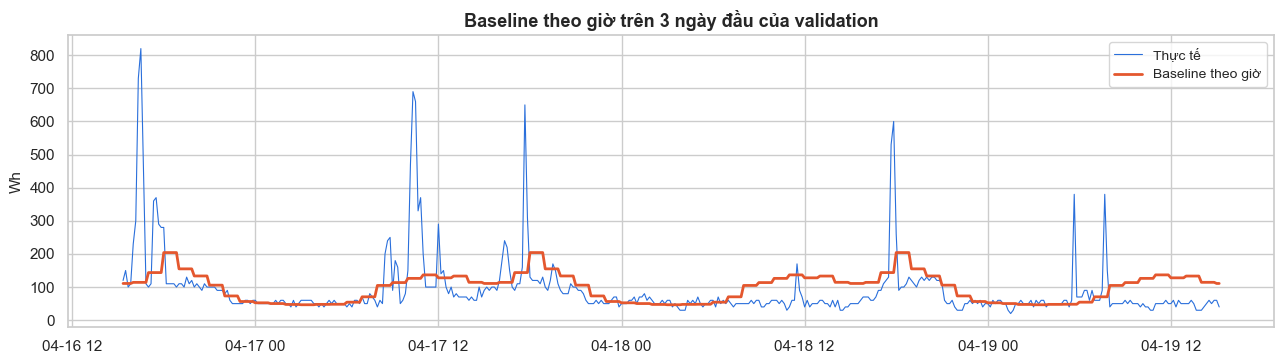

In [3]:
hb = HourMeanBaseline().fit(X_tr, y_tr)
day = val.iloc[: 6 * 24 * 3]  # 3 ngày đầu của validation
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(day["date"], day["Appliances"], linewidth=0.8, label="Thực tế")
ax.plot(day["date"], hb.predict(make_xy(day)[0]), linewidth=2, label="Baseline theo giờ")
ax.set_title("Baseline theo giờ trên 3 ngày đầu của validation")
ax.set_ylabel("Wh")
ax.legend()
fig.tight_layout()
save_fig(fig, "04_baseline_hour")
plt.show()

**Nhận xét:**
- Baseline trung bình: RMSE ≈ 92,4 Wh, R² ≈ 0 – đúng như định nghĩa.
- Baseline theo giờ: RMSE ≈ 87,2 Wh, MAE ≈ 48,5 Wh, R² ≈ 0,11. Chỉ cần biết **giờ trong ngày** đã giải thích được
  ~11% phương sai.
- Baseline theo giờ chỉ vẽ được "hình dạng trung bình" của một ngày, không bắt được các đỉnh nhọn ngẫu nhiên
  (lúc bật máy giặt, lò nướng, ...). Đây là mốc mà các mô hình học máy **phải vượt qua**.

## 2. Mô hình tuyến tính
Dùng Pipeline (chuẩn hóa + one-hot) và đánh giá bằng:
- **CV:** `TimeSeriesSplit` 5 fold trên train (trung bình ± độ lệch chuẩn) – đo độ ổn định.
- **Validation:** huấn luyện trên toàn bộ train, đánh giá trên validation.

In [4]:
from sklearn.linear_model import Lasso, LinearRegression, Ridge

from src.preprocessing import make_pipeline
from src.train import cv_evaluate, fit_and_validate

linear_models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1)": Ridge(alpha=1.0),
    "Ridge (alpha=100)": Ridge(alpha=100.0),
    "Lasso (alpha=0.5)": Lasso(alpha=0.5, max_iter=10000),
    "Lasso (alpha=1)": Lasso(alpha=1.0, max_iter=10000),
}
lin_results, fitted = {}, {}
for name, model in linear_models.items():
    pipe = make_pipeline(model, cols, kind="linear")
    fitted[name], r = fit_and_validate(pipe, X_tr, y_tr, X_va, y_va)
    r.update(cv_evaluate(pipe, X_tr, y_tr))
    lin_results[name] = r

show = ["train_RMSE", "train_R2", "cv_RMSE", "cv_RMSE_std", "cv_R2", "val_RMSE", "val_MAE", "val_R2"]
pd.DataFrame(lin_results).T[show].round(3)

,train_RMSE,train_R2,cv_RMSE,cv_RMSE_std,cv_R2,val_RMSE,val_MAE,val_R2
Linear Regression,98.136,0.256,98.546,5.766,0.071,86.419,51.932,0.122
Ridge (alpha=1),98.140,0.256,98.410,5.655,0.074,86.368,51.892,0.123
Ridge (alpha=100),98.536,0.250,96.663,5.304,0.106,85.597,51.050,0.139
Lasso (alpha=0.5),98.648,0.248,96.662,5.261,0.106,84.929,49.710,0.152
Lasso (alpha=1),99.200,0.240,96.115,4.960,0.116,85.263,49.125,0.146


### 2.1 Ảnh hưởng của hệ số regularization alpha

Đã lưu hình: reports/figures/04_ridge_alpha.png


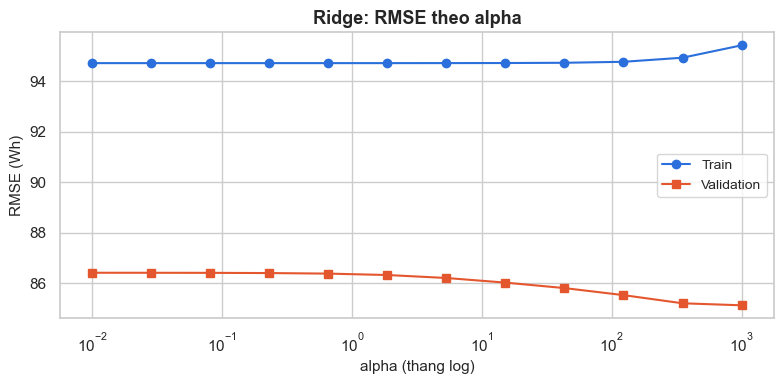

In [5]:
alphas = np.logspace(-2, 3, 12)
curve = []
for a in alphas:
    _, r = fit_and_validate(make_pipeline(Ridge(alpha=a), cols, "linear"), X_tr, y_tr, X_va, y_va)
    curve.append((a, r["train_RMSE"], r["val_RMSE"]))
curve = pd.DataFrame(curve, columns=["alpha", "train", "validation"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(curve["alpha"], curve["train"], marker="o", label="Train")
ax.semilogx(curve["alpha"], curve["validation"], marker="s", label="Validation")
ax.set_title("Ridge: RMSE theo alpha")
ax.set_xlabel("alpha (thang log)")
ax.set_ylabel("RMSE (Wh)")
ax.legend()
fig.tight_layout()
save_fig(fig, "04_ridge_alpha")
plt.show()

**Nhận xét:**
- Mọi mô hình tuyến tính chỉ đạt **R² validation ≈ 0,12–0,15**, RMSE ≈ 85–86 Wh – **chỉ nhỉnh hơn baseline theo
  giờ** (87,2 Wh). Bài báo gốc cũng báo cáo hồi quy tuyến tính kém nhất trong các mô hình.
- Train RMSE (~98) **cao hơn** validation RMSE (~85): không phải overfitting, mà do validation ít đỉnh lớn hơn train
  (RMSE baseline cũng 106,9 → 92,4). Mô hình tuyến tính đang **underfit** – quá đơn giản cho quan hệ phi tuyến
  (đúng như dự đoán từ EDA: Spearman > Pearson).
- Tăng regularization (Ridge alpha lớn, Lasso) giúp validation tốt lên chút ít: giảm phương sai do đa cộng tuyến.
- Độ lệch chuẩn RMSE qua 5 fold ≈ 5 Wh → kết quả **khá ổn định** giữa các giai đoạn thời gian.

## 3. Phân tích hệ số
Vì đã chuẩn hóa, hệ số cho biết: tăng 1 độ lệch chuẩn của đặc trưng → dự đoán thay đổi bao nhiêu Wh.

In [6]:
def coef_series(pipe):
    names = pipe.named_steps["prep"].get_feature_names_out()
    return pd.Series(pipe.named_steps["model"].coef_, index=names)

coefs = pd.DataFrame({
    "Linear": coef_series(fitted["Linear Regression"]),
    "Ridge(100)": coef_series(fitted["Ridge (alpha=100)"]),
    "Lasso(1)": coef_series(fitted["Lasso (alpha=1)"]),
})
coefs = coefs.reindex(coefs["Ridge(100)"].abs().sort_values(ascending=False).index)
coefs.round(2).head(12)

,Linear,Ridge(100),Lasso(1)
T3,38.00,36.44,27.61
RH_3,33.69,29.80,12.72
RH_1,32.83,28.81,16.55
RH_2,-35.36,-28.74,-11.58
hour_cos,-27.00,-25.94,-22.93
T9,-26.47,-22.39,-10.41
hour_sin,-19.95,-20.23,-20.33
lights,16.75,16.90,17.11
T2,-20.95,-15.61,-4.00
T8,16.63,15.41,6.14


Đã lưu hình: reports/figures/04_ridge_coefficients.png


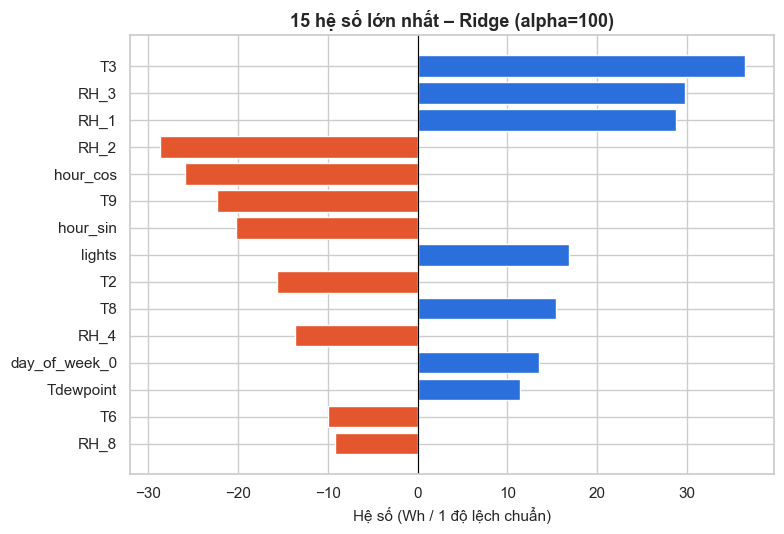

In [7]:
top = coefs["Ridge(100)"].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color=["#e4572e" if v < 0 else "#2a6fdb" for v in top.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("15 hệ số lớn nhất – Ridge (alpha=100)")
ax.set_xlabel("Hệ số (Wh / 1 độ lệch chuẩn)")
fig.tight_layout()
save_fig(fig, "04_ridge_coefficients")
plt.show()

In [8]:
lasso_zero = coefs.index[coefs["Lasso(1)"].abs() < 1e-6].tolist()
print(f"Lasso(alpha=1) loại {len(lasso_zero)} / {len(coefs)} đặc trưng (hệ số = 0):")
print(lasso_zero)
print("Hệ số rv1 – Linear:", round(coefs.loc['rv1', 'Linear'], 3), "| Lasso:", round(coefs.loc['rv1', 'Lasso(1)'], 3))

Lasso(alpha=1) loại 12 / 37 đặc trưng (hệ số = 0):
['Tdewpoint', 'RH_6', 'day_of_week_4', 'day_of_week_5', 'day_of_week_6', 'day_of_week_2', 'Press_mm_hg', 'T_out', 'T7', 'nsm', 'RH_5', 'rv1']
Hệ số rv1 – Linear: -0.63 | Lasso: -0.0


**Nhận xét:**
- Các cặp đặc trưng tương quan mạnh nhận hệ số **lớn và trái dấu nhau**: `RH_1` (+33) với `RH_2` (−35),
  `T3` (+38) với `T9` (−26) – `T9` tương quan r > 0,9 với `T3`. Đây là dấu hiệu của **đa cộng tuyến**: các biến
  "bù trừ" cho nhau nên không thể diễn giải từng hệ số riêng lẻ.
- **Ridge** co các hệ số lại một chút; **Lasso** co mạnh hơn (vd. `RH_2` −35 → −12) và đưa **12/37** hệ số về 0,
  trong đó có `T_out`, `Press_mm_hg`, `Tdewpoint` (trùng thông tin với cảm biến khác) và `rv1` → chọn đặc trưng
  tự động, loại đúng biến ngẫu nhiên.
- Đặc trưng giờ (`hour_sin`, `hour_cos`) và `lights` có hệ số ổn định qua cả 3 mô hình → tín hiệu đáng tin cậy.
  `day_of_week_0` (Thứ Hai) dương ~+13 Wh, khớp với EDA (Thứ Hai tiêu thụ cao nhất).
- Hạn chế: mô hình tuyến tính giả định quan hệ thẳng, trong khi EDA cho thấy quan hệ phi tuyến và phụ thuộc theo
  giờ → cần mô hình phi tuyến (cây, ensemble) – **RQ2** sẽ kiểm chứng ở notebook 05.